# Sentiment Analysis of McDonald's Reviews
### Part 1: Rule-Based Approach

CS Elective 2

We have 33,396 Google reviews of McDonald's stores in the US, each with a 1-5 star rating. The goal is to classify each review as **positive or negative**.

In this notebook we use a **rule-based** approach: the computer doesn't learn anything. It looks up words in a dictionary of sentiment scores and applies fixed rules (for example, "not" flips the meaning of the next word). We start with the well-known VADER tool and improve it step by step.

The semantic approach (a neural network) is in the second notebook, where we also compare the two.

## Setup

Runs on Google Colab or locally in VS Code (kernel `sentiment_env`). On Colab, set `DRIVE_FOLDER` to the Google Drive folder that has `McDonald_s_Reviews.csv`. This notebook doesn't need a GPU.

In [1]:
import os
import sys

DRIVE_FOLDER = "/content/drive/MyDrive/Sentiment Analysis"
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(DRIVE_FOLDER)
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment"])

import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer, NEGATE, BOOSTER_DICT

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)
SEED = 42
print("working folder:", os.getcwd())

working folder: /home/codrei/my_first_ml_project/CS_ELECTIVE_2/Sentiment Analysis


---
## 1. The data

The file isn't saved in UTF-8, so the normal `read_csv` fails. We load it with `latin-1` instead.

In [2]:
raw = pd.read_csv("McDonald_s_Reviews.csv", encoding="latin-1")
raw.columns = raw.columns.str.strip()    # 'latitude ' had an extra space
print(raw.shape)
raw[["store_address", "review", "rating"]].head()

(33396, 10)


,store_address,review,rating
0,"13749 US-183 Hwy, Austin, TX 78750, United States","Why does it look like someone spit on my food?\nI had a normal transaction, everyone was chill and polite, but now i dont want to eat t...",1 star
1,"13749 US-183 Hwy, Austin, TX 78750, United States","It'd McDonalds. It is what it is as far as the food and atmosphere go. The staff here does make a difference. They are all friendly, acc...",4 stars
2,"13749 US-183 Hwy, Austin, TX 78750, United States",Made a mobile order got to the speaker and checked it in.\nLine was not moving so I had to leave otherwise Iï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï...,1 star
3,"13749 US-183 Hwy, Austin, TX 78750, United States",My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿...,5 stars
4,"13749 US-183 Hwy, Austin, TX 78750, United States","I repeat my order 3 times in the drive thru, and she still manage to mess it up , it was suppose to be a large meal double filet of fish...",1 star


In [3]:
raw.isna().sum()

reviewer_id        0
store_name         0
category           0
store_address      0
latitude         660
longitude        660
rating_count       0
review_time        0
review             0
rating             0
dtype: int64

Only latitude and longitude have missing values (660 rows, all from one store). We only need the review text and the rating, which are complete, so we didn't drop anything.

### Cleaning the text

About 3,000 reviews have broken characters (`ï¿½`) where apostrophes and emojis used to be. Between two letters it was usually an apostrophe ("Iï¿½d" → "I'd"), so we put that back, and replaced the rest with a space. For a rule-based method this matters a lot: "don't" has to be readable as a negation.

In [4]:
def clean(text):
    text = re.sub(r"(?<=[A-Za-z])[ï¿½]+(?=[A-Za-z])", "'", text)
    text = re.sub(r"[ï¿½]+", " ", text)
    return " ".join(text.split())

print("before:", raw.loc[2, "review"][100:150])
raw["review"] = raw["review"].apply(clean)
print("after: ", raw.loc[2, "review"][90:130])

before: rwise Iï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï


after:  leave otherwise I'd be late for work. Ne


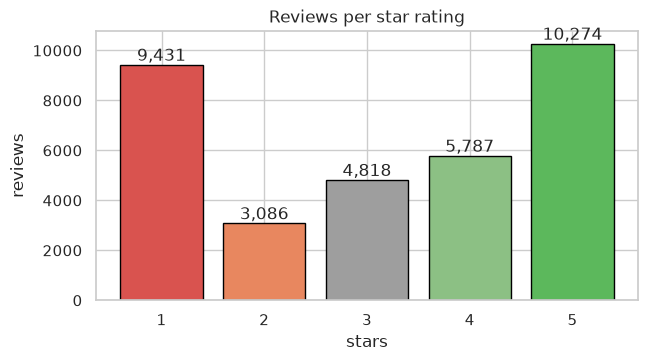

In [5]:
raw["stars"] = raw["rating"].str[0].astype(int)
counts = raw["stars"].value_counts().sort_index()

plt.figure(figsize=(7, 3.5))
bars = plt.bar(counts.index, counts.values, color=["#d9534f", "#e8875f", "#9e9e9e", "#8cc084", "#5cb85c"], edgecolor="black")
plt.bar_label(bars, labels=[f"{c:,}" for c in counts.values])
plt.title("Reviews per star rating")
plt.xlabel("stars")
plt.ylabel("reviews")
plt.show()

We turned the stars into labels: **1-2 stars = negative**, **4-5 stars = positive**. We left out 3-star reviews because they are usually mixed ("food was fine but slow") and don't have a clear right answer. Public review datasets like the Amazon Review Polarity dataset are built the same way.

### Duplicate reviews

In [6]:
words = ["Terrible", "Poor", "Neutral", "Good", "Excellent"]
subset = raw[raw["review"].isin(words)]
pd.crosstab(subset["review"], subset["stars"]).loc[words]

stars,1,2,3,4,5
review,,,,,
Terrible,290,1,0,0,1
Poor,1,316,0,0,0
Neutral,0,0,942,0,0
Good,3,4,17,1307,85
Excellent,0,0,1,1,2164


When someone leaves only stars on Google, the text gets filled in with a word that matches the rating. That's about 5,000 reviews nobody actually wrote. We kept **one copy of each text**, labeled with the sentiment most of its copies have. Otherwise the same text would be in both the data we build our rules from and the data we test on.

In [7]:
raw["sentiment"] = raw["stars"].map({1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"})
majority = raw.groupby("review")["sentiment"].agg(lambda s: s.value_counts().index[0])
share = raw.groupby("review")["sentiment"].agg(lambda s: s.value_counts(normalize=True).iloc[0])

df = raw.drop_duplicates("review").copy()
df["sentiment"] = df["review"].map(majority)
df = df[df["review"].map(share) > 0.5].reset_index(drop=True)
df[["review", "stars", "sentiment", "store_address"]].to_csv("mcdo_reviews_clean.csv", index=False)
print("before:", len(raw), " after removing duplicates:", len(df))

before: 33396  after removing duplicates: 22111


### Splitting the data

Even though a rule-based method doesn't train, we still split the data, because we **build and tune** the rules using data:

- **train (70%)**: used to find words and phrases that VADER is missing
- **validation (15%)**: used to choose settings, like the cut-off between positive and negative
- **test (15%)**: used **once** at the end, for the final score

If we built the rules and measured them on the same reviews, the score would look better than it really is. The semantic notebook uses exactly the same split, so the comparison is fair.

In [8]:
labels3 = df["sentiment"].map({"negative": 0, "neutral": 1, "positive": 2}).values
X_train, X_temp, y_train, y_temp = train_test_split(df["review"], labels3, test_size=0.30, stratify=labels3, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

def drop_neutral(X, y):
    keep = y != 1
    return X[keep].tolist(), (y[keep] == 2).astype(int)     # negative = 0, positive = 1

X_train, y_train = drop_neutral(X_train, y_train)
X_val, y_val = drop_neutral(X_val, y_val)
X_test, y_test = drop_neutral(X_test, y_test)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} {len(y):6,} reviews, {y.mean():.1%} positive")

train 13,314 reviews, 50.6% positive
val    2,853 reviews, 50.6% positive
test   2,854 reviews, 50.6% positive


---
## 2. Starting point: VADER

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) is a widely used rule-based sentiment tool. It has a dictionary of about 7,500 words, each scored by people from -4 (very negative) to +4 (very positive). To score a sentence it adds up the word scores, with rules like these:

- **negation:** "not", "never" or "isn't" before a word flips it and makes it weaker
- **intensifiers:** "very" makes the next word stronger, "kind of" makes it weaker
- **"but":** words after "but" count more than words before it
- **CAPS and "!"** make the sentiment stronger

At the end VADER squashes the total into a **compound score** from -1 to +1.

In [9]:
vader = SentimentIntensityAnalyzer()

examples = ["The food was good", "The food was not good", "The food was VERY good!!!",
            "The food was good but the service was terrible", "I waited 40 minutes for cold fries"]
for s in examples:
    print(f"{vader.polarity_scores(s)['compound']:+.3f}   {s}")

+0.440   The food was good
-0.341   The food was not good
+0.701   The food was VERY good!!!
-0.494   The food was good but the service was terrible
+0.000   I waited 40 minutes for cold fries


The rules work on the first four. The last one scores **0**, because "waited", "minutes", "cold" and "fries" aren't in VADER's dictionary, even though it's obviously a complaint.

VADER's documentation calls a text positive when the compound score is at least 0.05:

In [10]:
val_vader = np.array([vader.polarity_scores(t)["compound"] for t in X_val])
results = [["1. Plain VADER", accuracy_score(y_val, val_vader >= 0.05)]]
print(f"plain VADER validation accuracy: {results[-1][1]:.4f}")
print(f"reviews with a score of exactly 0: {(val_vader == 0).mean():.1%}")

plain VADER validation accuracy: 0.7932
reviews with a score of exactly 0: 16.1%


About 79%, and for 16% of the reviews VADER doesn't find a single sentiment word.

---
## 3. Adding restaurant words by hand

VADER was made for general text. In restaurant reviews, words like "waited", "slow" and "cold" are clearly negative, and "fast" and "tasty" are positive, but VADER doesn't know them. We first added 27 of these words by hand, plus one rule for "never coming back" / "never again".

In [11]:
HAND_WORDS = {
    "waited": -1.5, "waiting": -1.0, "forever": -1.5, "minutes": -1.0, "mins": -1.0, "min": -1.0,
    "hour": -1.0, "slow": -1.5, "slowest": -2.5, "cold": -1.5, "stale": -2.0, "soggy": -2.0,
    "burnt": -2.0, "overpriced": -2.0, "refund": -1.5, "forgot": -1.5, "missing": -1.5,
    "fast": 1.5, "quick": 1.5, "quickly": 1.5, "efficient": 1.5, "hot": 1.0,
    "tasty": 2.0, "convenient": 1.5, "polite": 2.0, "courteous": 2.0, "professional": 1.5,
}
NEVER_AGAIN = re.compile(r"\bnever (again|coming back|come back|go(ing)? back|return)", re.IGNORECASE)

hand = SentimentIntensityAnalyzer()
hand.lexicon.update(HAND_WORDS)
val_hand = np.array([hand.polarity_scores(t)["compound"] - (0.5 if NEVER_AGAIN.search(t) else 0) for t in X_val])

def best_threshold(scores, labels):
    # try many cut-offs (between the 20th and 80th percentile of the scores) and keep the best one
    candidates = np.quantile(scores, np.linspace(0.2, 0.8, 121))
    accs = [accuracy_score(labels, scores > c) for c in candidates]
    return candidates[int(np.argmax(accs))]

th_hand = best_threshold(val_hand, y_val)
results.append(["2. + 27 hand-picked words, 'never again' rule", accuracy_score(y_val, val_hand > th_hand)])
print(f"validation accuracy: {results[-1][1]:.4f}  (cut-off {th_hand:.2f})")
print(f"I waited 40 minutes for cold fries -> {hand.polarity_scores('I waited 40 minutes for cold fries')['compound']:+.3f}")

validation accuracy: 0.8335  (cut-off 0.23)
I waited 40 minutes for cold fries -> -0.718


That helped, to about 83%. But there are thousands of words people use in reviews, and we can't score them all by hand.

---
## 4. Building a bigger dictionary from the training reviews

This is a common way to build a sentiment dictionary for a specific domain (a **corpus-based lexicon**). Instead of guessing a score for every word, we calculate it from how often the word appears in positive vs negative **training** reviews:

`score = 0.5 × log( share of positive reviews with the word / share of negative reviews with the word )`

- a word that appears equally in both gets 0
- a word that's 3 times more common in negative reviews gets about -0.55
- the result is kept between -4 and +4, the same scale VADER uses

We only add words that appear in at least 5 training reviews and lean clearly one way (at least 2.7 times more common in one class), and we don't change any of VADER's own words. The scoring rules (negation, "but", intensifiers, CAPS) stay exactly the same, and they now also apply to our new words.

**One thing we had to be careful about:** negation words like "not", "didn't" and "wasn't" also lean negative in our data, because complaints use them a lot. But when we first added them to VADER's dictionary, VADER stopped flipping "not bad", since VADER only treats a word as a negation if it is *not* in the dictionary. So we keep negation words (and words like "very" and "extremely") out of the dictionary and give them their points separately. That way they still count, and VADER's negation rule keeps working.

In [12]:
def tokenize(text):
    return re.findall(r"[a-z']+", text.lower())

def ngrams(text, n):
    w = tokenize(text)
    return set(zip(*[w[i:] for i in range(n)]))

def log_odds(counter_pos, counter_neg):
    P, N = y_train.sum(), (1 - y_train).sum()
    return {k: (np.log((counter_pos[k] + 1) / (P + 2)) - np.log((counter_neg[k] + 1) / (N + 2)), counter_pos[k] + counter_neg[k])
            for k in set(counter_pos) | set(counter_neg)}

counts = {n: (Counter(), Counter()) for n in [1, 2, 3]}
for text, label in zip(X_train, y_train):
    for n in [1, 2, 3]:
        grams = set(tokenize(text)) if n == 1 else ngrams(text, n)
        counts[n][0 if label == 1 else 1].update(grams)

word_lo = log_odds(*counts[1])
SPECIAL = set(NEGATE) | {w.replace("'", "") for w in NEGATE} | set(BOOSTER_DICT) | {"no"}   # VADER's negation and intensifier words
scored = {w: float(np.clip(0.5 * lo, -4, 4)) for w, (lo, n) in word_lo.items()
          if n >= 5 and abs(lo) >= 1.0 and w not in vader.lexicon}
CORPUS_WORDS = {w: s for w, s in scored.items() if w not in SPECIAL}
NEGATION_WORDS = {w: s for w, s in scored.items() if w in SPECIAL}
print("new words added to the dictionary:", len(CORPUS_WORDS))
print("negation/intensifier words scored separately:", len(NEGATION_WORDS),
      {w: round(NEGATION_WORDS[w], 2) for w in ["not", "didn't", "wasn't", "never"] if w in NEGATION_WORDS})

table = pd.Series(CORPUS_WORDS).sort_values()
print("\nmost negative new words:", ", ".join(f"{w} ({s:+.1f})" for w, s in table.head(15).items()))
print("\nmost positive new words:", ", ".join(f"{w} ({s:+.1f})" for w, s in table.tail(15)[::-1].items()))
print("\nsome everyday words:", {w: round(CORPUS_WORDS[w], 2) for w in ["waited", "minutes", "cold", "manager", "fast", "quick", "tasty"] if w in CORPUS_WORDS})

new words added to the dictionary: 1042
negation/intensifier words scored separately: 44 {'not': -0.64, "didn't": -0.63, "wasn't": -0.63, 'never': -0.74}

most negative new words: disrespectful (-2.0), answer (-1.7), filthy (-1.7), answered (-1.7), raw (-1.7), slowest (-1.7), yelled (-1.6), response (-1.6), acknowledge (-1.6), zero (-1.5), poorly (-1.5), pulled (-1.5), gloves (-1.5), manners (-1.5), hung (-1.5)

most positive new words: speedy (+1.5), affordable (+1.4), prompt (+1.3), oven (+1.3), yum (+1.3), attentive (+1.2), customize (+1.2), variety (+1.1), digital (+1.1), tasty (+1.1), breakfasts (+1.1), portuguese (+1.1), cozy (+1.1), peak (+1.1), smooth (+1.1)

some everyday words: {'waited': -1.35, 'minutes': -1.08, 'cold': -1.17, 'manager': -0.77, 'fast': 0.73, 'quick': 1.08, 'tasty': 1.11}


Most of the new words make sense: waiting and service problems on the negative side ("disrespectful", "yelled", "answer" from nobody answering the phone), speed and taste on the positive side. 21 of our 27 hand-picked words were found automatically, now with scores based on the data instead of our guesses.

Some words are odd, though. "Portuguese", "rice" and "oven" lean positive only because a few stores with good reviews sell those items. This is the weakness of building a dictionary from data: it picks up whatever happens to appear more in one class, whether it's really about sentiment or not. A person checking the list would remove them. We left them in so the list is built by one clear formula, not by our own picking.

**Changing how we read the score.** With over 1,000 extra words, many more reviews get pushed close to -1 or +1 by VADER's squash (about 16% of reviews go past ±0.9, compared to 5% with plain VADER), so it gets harder to tell a strong review from a mild one. When we tried the squashed compound score with the big dictionary, accuracy actually went *down* to 76-82%. So we use the **total before squashing**, divided by the square root of the review's length, so that long reviews don't win just by having more words.

In [13]:
class RawVader(SentimentIntensityAnalyzer):
    # same VADER rules, but also returns the total before it gets squashed into -1..+1
    def score_valence(self, sentiments, text):
        result = super().score_valence(sentiments, text)
        total = float(sum(sentiments)) if sentiments else 0.0
        if total:
            punct = self._punctuation_emphasis(text)
            total = total + punct if total > 0 else total - punct
        result["raw"] = total
        return result

rules = RawVader()
rules.lexicon.update(CORPUS_WORDS)

def length_factor(texts):
    return np.sqrt(np.array([max(1, len(t.split())) for t in texts]))

def negation_points(text):
    return sum(NEGATION_WORDS.get(w, 0) for w in tokenize(text))

val_words = np.array([rules.polarity_scores(t)["raw"] + negation_points(t) for t in X_val])
s = val_words / length_factor(X_val)
th = best_threshold(s, y_val)
results.append(["3. + ~1,080 words scored from training reviews", accuracy_score(y_val, s > th)])
print(f"validation accuracy: {results[-1][1]:.4f}")
print(f"reviews with a score of exactly 0: {(val_words == 0).mean():.1%}")

validation accuracy: 0.8784
reviews with a score of exactly 0: 4.1%


A big jump to about 87%.

---
## 5. Phrase rules

VADER's dictionary only has single words, but some meanings come from word combinations: "wrong order", "drive thru", "no ice", "not fresh". We scored two-word and three-word phrases the same way.

We only keep a phrase if it says something **its words don't already say on their own**. For example, "wrong order" is more negative than "wrong" and "order" separately, so it gets an extra score. "Really good" doesn't, because "good" already covers it.

In [14]:
pair_lo = log_odds(*counts[2])
PHRASES_2 = {}
for pair, (lo, n) in pair_lo.items():
    if n < 10 or abs(lo) < 1.0:
        continue
    extra = lo - word_lo.get(pair[0], (0, 0))[0] - word_lo.get(pair[1], (0, 0))[0]
    if abs(extra) >= 0.5:
        PHRASES_2[pair] = float(np.clip(0.5 * extra, -4, 4))

PHRASES_3 = {tri: float(np.clip(0.3 * lo, -4, 4)) for tri, (lo, n) in log_odds(*counts[3]).items()
             if n >= 10 and abs(lo) >= 1.5}

print("two-word phrases:", len(PHRASES_2), "   three-word phrases:", len(PHRASES_3))
p2 = pd.Series({" ".join(k): v for k, v in PHRASES_2.items()}).sort_values()
print("\nexamples (2 words):", ", ".join(f"{w} ({s:+.1f})" for w, s in pd.concat([p2.head(8), p2.tail(8)]).items()))
p3 = pd.Series({" ".join(k): v for k, v in PHRASES_3.items()}).sort_values()
print("\nexamples (3 words):", ", ".join(f"{w} ({s:+.1f})" for w, s in pd.concat([p3.head(6), p3.tail(6)]).items()))

def phrase_points(text):
    return 1.5 * sum(PHRASES_2.get(p, 0) for p in ngrams(text, 2)) + sum(PHRASES_3.get(p, 0) for p in ngrams(text, 3))

s = (val_words + np.array([phrase_points(t) for t in X_val])) / length_factor(X_val)
th = best_threshold(s, y_val)
results.append(["4. + two- and three-word phrase rules", accuracy_score(y_val, s > th)])
print(f"\nvalidation accuracy: {results[-1][1]:.4f}")

two-word phrases: 1258    three-word phrases: 740

examples (2 words): not fresh (-1.5), not friendly (-1.5), no good (-1.3), clean it (-1.2), to clean (-1.2), not clean (-1.1), always out (-1.0), only good (-1.0), any issues (+1.8), can't go (+1.8), worst ever (+1.8), bit slow (+2.0), my go (+2.0), little slow (+2.0), not bad (+2.2), go wrong (+2.3)

examples (3 words): the worst mcdonald's (-1.4), is the worst (-1.2), i will never (-1.1), worst mcdonald's i've (-1.1), was very rude (-1.1), horrible customer service (-1.0), friendly and helpful (+1.0), and friendly service (+1.0), was fast and (+1.0), and good service (+1.0), clean and the (+1.0), good food and (+1.1)

validation accuracy: 0.8878


Remember that a phrase's score is only the **extra** meaning beyond its words, so it can be a correction in either direction:

- "not fresh" and "not friendly" get extra **negative** points, because "fresh" and "friendly" on their own count as positive.
- "not bad" and "go wrong" (from "you can't go wrong") get extra **positive** points, because "bad" and "wrong" on their own count as negative.
- "worst ever" also gets **positive** points. That doesn't mean it's a nice phrase: "worst" and "ever" are each already strongly negative, and the correction stops the review from being punished twice for the same thing.
- "bit slow" and "little slow" are positive corrections too. People write "a bit slow but the food was great" in good reviews, so "a bit slow" is much milder than "slow" on its own.

A hand-written rule list would probably have missed most of these.

---
## 6. Pattern rules

Looking at the reviews the rules still got wrong, we noticed some patterns that a word list can't catch, so we wrote them as regular expressions:

In [15]:
PATTERNS = [
    ("a number of minutes/hours (waiting time)", r"\b\d+\s*(minutes|mins?|hours?|hrs?)\b", -1.5),
    ("could have been better / needs improvement", r"\b(could|should)\s*(have|of|'ve)?\s*been better|\bcould be better|needs? (some |more |a lot of )?improvement", -2.0),
    ("the only good thing", r"\bonly (good|thing good|positive)", -2.0),
    ("too long / too slow / too expensive", r"\bto+o? (long|slow|high|expensive|much|small|little|busy|pricey|salty|greasy)\b", -1.5),
    ("never again / never coming back", r"\bnever (again|coming back|come back|go(ing)? back|return)", -2.0),
    ("better than expected", r"\bbetter than (i |we )?(expected|thought|most|other|average|usual)", 1.5),
    ("no complaints / can't complain", r"\bno complaints?\b|\bcan'?t complain\b", 2.0),
]
PATTERNS = [(name, re.compile(rx, re.IGNORECASE), points) for name, rx, points in PATTERNS]

def pattern_points(text):
    return sum(points for _, rx, points in PATTERNS if rx.search(text))

for name, rx, points in PATTERNS:
    print(f"{points:+.1f}  {name:45s} found in {sum(bool(rx.search(t)) for t in X_val):3d} validation reviews")

-1.5  a number of minutes/hours (waiting time)      found in 262 validation reviews
-2.0  could have been better / needs improvement    found in   5 validation reviews
-2.0  the only good thing                           found in   5 validation reviews
-1.5  too long / too slow / too expensive           found in  33 validation reviews
-2.0  never again / never coming back               found in  26 validation reviews
+1.5  better than expected                          found in   3 validation reviews
+2.0  no complaints / can't complain                found in   6 validation reviews


Notice that the "too long" rule also matches "**to** long", a common typo in reviews.

### Two more rules

1. **Star ratings written in the text.** Some people write their rating in the review itself, like "5 stars", "zero stars" or "10/10". If the review mentions 1-2 stars (or 0-4 out of 10) it gets -3 points; 4-5 stars (or 7-10 out of 10) gets +3.
2. **Question marks.** Reviews with a question are usually complaints ("Why does it look like someone spit on my food?", "How hard is it to get an order right?"). A review with a "?" gets -1 point.

In [16]:
STARS = re.compile(r"\b(\d|zero|one|two|three|four|five)\s*(stars?|\*)", re.IGNORECASE)
OUT_OF_10 = re.compile(r"\b(\d{1,2})\s*/\s*10\b")
NUMBER_WORDS = {"zero": 0, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5}

def star_points(text):
    m = STARS.search(text)
    if m:
        n = int(m.group(1)) if m.group(1).isdigit() else NUMBER_WORDS[m.group(1).lower()]
        if n <= 2:
            return -3.0
        if 4 <= n <= 5:
            return 3.0
    m = OUT_OF_10.search(text)
    if m:
        n = int(m.group(1))
        if n <= 4:
            return -3.0
        if 7 <= n <= 10:
            return 3.0
    return 0.0

def question_points(text):
    return -1.0 if "?" in text else 0.0

stars_val = np.array([star_points(t) for t in X_val])
quest_val = np.array([question_points(t) for t in X_val])
fires = stars_val != 0
print(f"star rule: found in {fires.sum()} validation reviews, and it points the right way in {((stars_val[fires] > 0) == y_val[fires]).mean():.0%} of them")
print(f"question rule: found in {(quest_val != 0).sum()} validation reviews, {1 - y_val[quest_val != 0].mean():.0%} of them are negative")

star rule: found in 61 validation reviews, and it points the right way in 95% of them
question rule: found in 97 validation reviews, 80% of them are negative


## 7. The final rule-based score

Putting it all together:

`score = (VADER total + 1.5 × negation-word points + phrase points + 1.5 × pattern points + star points + question points) / √(number of words)`

The 1.5× weights for negation words and pattern rules were chosen on the validation set: we tried 1 and 1.5 for each, and 1.5 worked a little better. The review is **positive if the score is above the cut-off**, also picked on the validation set.

In [17]:
def rule_based_score(texts, w_negation=1.5, w_patterns=1.5, extra_rules=True):
    totals = []
    for t in texts:
        total = rules.polarity_scores(t)["raw"] + w_negation * negation_points(t) + phrase_points(t) + w_patterns * pattern_points(t)
        if extra_rules:
            total += star_points(t) + question_points(t)
        totals.append(total)
    return np.array(totals) / length_factor(texts)

s = rule_based_score(X_val, w_negation=1.0, w_patterns=1.0, extra_rules=False)
results.append(["5. + pattern rules", accuracy_score(y_val, s > best_threshold(s, y_val))])

val_final = rule_based_score(X_val)
THRESHOLD = best_threshold(val_final, y_val)
results.append(["6. + star and question rules, 1.5x weights (final)", accuracy_score(y_val, val_final > THRESHOLD)])

steps = pd.DataFrame(results, columns=["step", "validation accuracy"]).round(4)
print(f"final cut-off: {THRESHOLD:.3f}")
steps

final cut-off: -0.254


,step,validation accuracy
0,1. Plain VADER,0.7932
1,"2. + 27 hand-picked words, 'never again' rule",0.8335
2,"3. + ~1,080 words scored from training reviews",0.8784
3,4. + two- and three-word phrase rules,0.8878
4,5. + pattern rules,0.8899
5,"6. + star and question rules, 1.5x weights (final)",0.8945


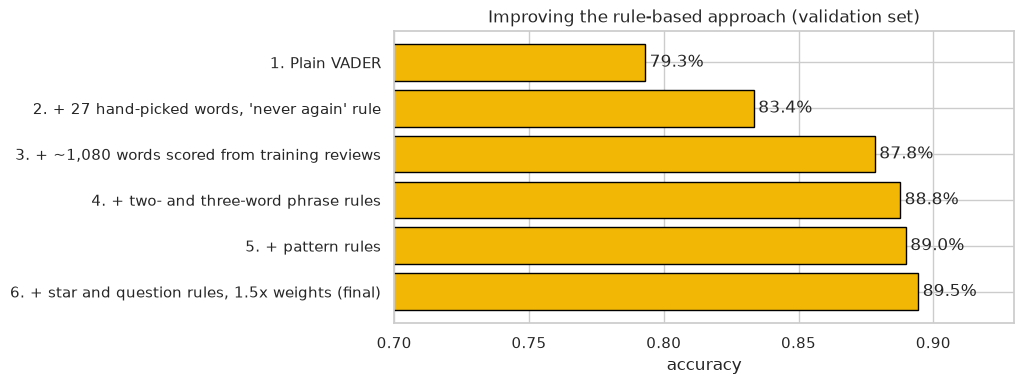

In [18]:
plt.figure(figsize=(8, 3.8))
bars = plt.barh(steps["step"][::-1], steps["validation accuracy"][::-1], color="#f2b705", edgecolor="black")
plt.bar_label(bars, labels=[f"{v:.1%}" for v in steps["validation accuracy"][::-1]], padding=3)
plt.xlim(0.7, 0.93)
plt.title("Improving the rule-based approach (validation set)")
plt.xlabel("accuracy")
plt.show()

The rules kept improving, but each step added less than the one before.

### Explaining a score

One good thing about rules: we can show exactly why a review got its score.

In [19]:
def explain(text):
    found = {w: round(rules.lexicon[w], 2) for w in tokenize(text) if w in rules.lexicon}
    found.update({w: round(NEGATION_WORDS[w], 2) for w in tokenize(text) if w in NEGATION_WORDS})
    p2 = {" ".join(p): round(1.5 * PHRASES_2[p], 2) for p in ngrams(text, 2) if p in PHRASES_2}
    p3 = {" ".join(p): round(PHRASES_3[p], 2) for p in ngrams(text, 3) if p in PHRASES_3}
    pats = [f"{name} ({1.5 * points:+})" for name, rx, points in PATTERNS if rx.search(text)]
    if star_points(text): pats.append(f"star rating in text ({star_points(text):+})")
    if question_points(text): pats.append(f"question mark ({question_points(text):+})")
    score = rule_based_score([text])[0]
    print(text)
    print("  words:", found)
    if p2 or p3: print("  phrases:", {**p2, **p3})
    if pats: print("  rules:", pats)
    print(f"  final score {score:+.2f} -> {'POSITIVE' if score > THRESHOLD else 'NEGATIVE'}  (word scores are then adjusted by VADER's rules, e.g. negation)\n")

explain("Took 25 minutes in the drive thru and they still got my order wrong")
explain("Fast service, friendly staff, and the fries were hot")
explain("The food was not bad at all")

Took 25 minutes in the drive thru and they still got my order wrong
  words: {'took': -0.77, 'minutes': -1.08, 'wrong': -2.1}
  phrases: {'order wrong': 0.7, 'they still': 0.42, 'thru and': -0.42, 'took minutes': 1.02, 'minutes in': -1.02, 'thru and they': -0.52, 'in the drive': -0.57, 'my order wrong': -0.56, 'drive thru and': -0.53, 'minutes in the': -1.04}
  rules: ['a number of minutes/hours (waiting time) (-2.25)']
  final score -2.33 -> NEGATIVE  (word scores are then adjusted by VADER's rules, e.g. negation)

Fast service, friendly staff, and the fries were hot
  words: {'fast': 0.73, 'friendly': 2.2}
  phrases: {'were hot': 0.82, 'service friendly': 0.38, 'fast service': 1.2, 'friendly staff and': 0.91}
  final score +2.08 -> POSITIVE  (word scores are then adjusted by VADER's rules, e.g. negation)

The food was not bad at all
  words: {'bad': -2.5, 'not': -0.64}
  phrases: {'not bad': 3.33, 'food was not': -0.49}
  final score +1.41 -> POSITIVE  (word scores are then adjusted 

In the first example, the phrase "took minutes" gets a positive score. That's because numbers are dropped when we split a review into words, so "took 5 minutes" (fast service, positive) and "took 25 minutes" look the same. The waiting-time pattern rule makes up for it, and the review still ends up clearly negative.

In the last example, "bad" (-2.5) is flipped by VADER's negation rule, and the phrase "not bad" adds extra positive points, so the review comes out positive.

---
## 8. Final results on the test set

All rules and settings were decided using the training and validation sets. Now we score each step on the test set, once.

In [20]:
test_vader = np.array([vader.polarity_scores(t)["compound"] for t in X_test])
test_hand = np.array([hand.polarity_scores(t)["compound"] - (0.5 if NEVER_AGAIN.search(t) else 0) for t in X_test])
test_final = rule_based_score(X_test)
pred_final = (test_final > THRESHOLD).astype(int)

test_table = pd.DataFrame({
    "approach": ["Plain VADER", "VADER + 27 hand-picked words", "Our final rule-based system"],
    "test accuracy": [accuracy_score(y_test, test_vader >= 0.05), accuracy_score(y_test, test_hand > th_hand), accuracy_score(y_test, pred_final)],
}).round(4)
test_table

,approach,test accuracy
0,Plain VADER,0.7961
1,VADER + 27 hand-picked words,0.8322
2,Our final rule-based system,0.8865


              precision    recall  f1-score   support

    negative      0.885     0.885     0.885      1409
    positive      0.888     0.888     0.888      1445

    accuracy                          0.886      2854
   macro avg      0.886     0.886     0.886      2854
weighted avg      0.886     0.886     0.886      2854



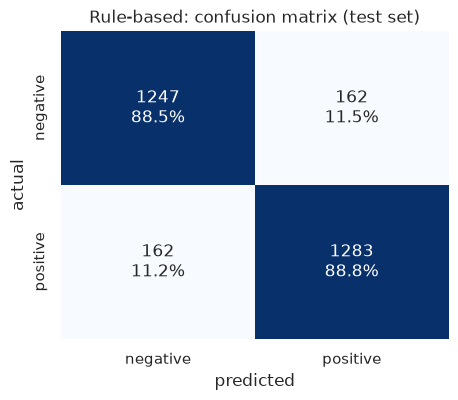

In [21]:
print(classification_report(y_test, pred_final, target_names=["negative", "positive"], digits=3))

cm = confusion_matrix(y_test, pred_final)
pct = cm / cm.sum(axis=1, keepdims=True)
annot = [[f"{cm[i, j]}\n{pct[i, j]:.1%}" for j in range(2)] for i in range(2)]
plt.figure(figsize=(5, 4))
sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", cbar=False, xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Rule-based: confusion matrix (test set)")
plt.show()

## 9. What the rules still get wrong

In [22]:
errors = pd.DataFrame({"review": X_test, "actual": np.where(y_test == 1, "positive", "negative"), "score": test_final.round(2)})
errors = errors[pred_final != y_test]
print("mistakes:", len(errors), "out of", len(y_test))
errors[errors["review"].str.split().str.len().between(4, 30)].sample(12, random_state=2)

mistakes: 324 out of 2854


,review,actual,score
1647,"Had to wait in line,but busy at all!!!",positive,-0.71
675,No issues good experience,positive,-1.30
120,"Order fresh, they give you old",negative,0.44
725,Why do you attend quickly?,positive,-0.84
1891,Just a regular McDonald restaurant Nothing special,positive,-0.28
382,Yes this was one of the least considerate places ive ever been. Not a very customer friendly place at.,negative,1.06
1321,They take a long time to give the food.,negative,-0.05
335,Very limited dine in seating.,positive,-0.53
1803,They accommodate UberEats by having the third window so we avoid the long drive thru line after 10pm.,positive,-0.59
145,A night to purchase your food,negative,-0.24


The remaining mistakes are mostly of three kinds:

1. **The meaning depends on the whole sentence**, like "They were fast, but my fries were cold", where good and bad words cancel out, or a complaint written without any negative words.
2. **Sarcasm and unusual wording**, which no word list can catch.
3. **The star rating doesn't match the text**, like a compliment left with 1 star. These are problems with the labels, and no method can fix them.

We tried many more ideas on the validation set, trying to reach 90%:

| idea | result on validation |
|---|---|
| bigger dictionary (looser filters, or keeping rare words with smaller scores) | worse |
| stronger word or phrase scores, more phrases | worse |
| changing VADER's own word scores where reviews disagree ("help", "care", "please" lean negative in complaints) | slightly worse |
| giving the last sentence more weight (people often end with their verdict) | worse |
| a rule for prices ("$30 for...") | no change |
| star-rating and question rules, 1.5× weights | **better, kept** |

None of them got past about 89.5%. Even machine learning models that only look at which words appear (like logistic regression) stopped at about 90% on this data, so a method based on word lists has a ceiling around there.

In [23]:
os.makedirs("model", exist_ok=True)
with open("model/rule_based.json", "w") as f:
    json.dump({"threshold": float(THRESHOLD), "weights": {"negation": 1.5, "patterns": 1.5},
               "corpus_words": CORPUS_WORDS, "negation_words": NEGATION_WORDS,
               "star_rules": {"stars": STARS.pattern, "out_of_10": OUT_OF_10.pattern, "points": 3.0}, "question_points": -1.0,
               "phrases_2": {" ".join(k): v for k, v in PHRASES_2.items()},
               "phrases_3": {" ".join(k): v for k, v in PHRASES_3.items()},
               "patterns": [[name, rx.pattern, points] for name, rx, points in PATTERNS]}, f, indent=1)
pd.DataFrame({"review": X_test, "label": y_test, "rule_score": test_final, "rule_pred": pred_final}).to_csv("model/rule_based_test_predictions.csv", index=False)
print("saved the rules to model/rule_based.json and the test predictions for the comparison notebook")

saved the rules to model/rule_based.json and the test predictions for the comparison notebook


---
## Conclusion

- Plain VADER got about 80% on our reviews. It works well for general text, but it doesn't know restaurant words like "waited", "slow" or "cold".
- We improved it in steps: hand-picked words, a dictionary of about 1,080 words scored from the training reviews, two- and three-word phrases, seven pattern rules, and rules for star ratings and question marks. Every rule is written down and can be checked.
- Our final rule-based system reached **88.6%** on the test set (89.4% on validation), up from 79.6% for plain VADER, without training any model.
- What rules can't handle is meaning that comes from context, sarcasm, and reviews whose stars don't match the text. That's where the semantic approach in the next notebook comes in.